# **Greenpod labs data science Assignment**


# Orange Fruit Image Classification — Two Approaches
**Scope note:** This notebook uses `Orange Dataset.zip` has two files first one is train data and second one is test data :with labels `fresh`, `blackspot`, `canker`, and `grenning`.

**The aim is to build a computer vision system that looks at a photo of an orange and says which of four conditions it has: fresh (healthy), blackspot, canker, or greening. **

For an **Avocado Ripening Stage Detection & Classification** This notebook is divided into two approches..

Two approaches are used, as the assignment requires.

**In Approach 1**: Classical computer vision + machine learning. I extract colour, texture and lesion features by hand and train an SVM and a Random Forest on them. That is one approach with two classifiers, which are compared against each other.


**In Approach 2**: Deep learning. MobileNetV2 transfer learning, where a pretrained neural network learns its own features from the images.

In [ ]:
!pip -q install scikit-image opencv-python-headless scikit-learn joblib

In [2]:
from google.colab import files
uploaded = files.upload()  # Select Orange Dataset.zip
ZIP_PATH = next((name for name in uploaded if name.lower().endswith('.zip')), None)
assert ZIP_PATH, "Please upload the dataset ZIP."
import zipfile, os
DATA_DIR = "/content/data"
os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)
print("Extracted entries:", len(os.listdir(DATA_DIR)))
print("Top-level:", os.listdir(DATA_DIR))


Saving Orange Dataset.zip to Orange Dataset (1).zip
Extracted entries: 2
Top-level: ['train', 'test']


## 1. Dataset audit: counts, unreadable files, dimensions, and class distribution

Using dataset root: /content/data


label,blackspot,canker,fresh,grenning
split,,,,
test,22,22,33,22
train,184,179,281,347


Readable images: 1090 Unreadable: 0


width                                                             \
       count        mean         std    min    25%    50%    75%    max   
split                                                                     
test    99.0  647.393939  223.026576  178.0  432.0  800.0  800.0  800.0   
train  991.0  671.182644  210.366198  144.0  458.0  800.0  800.0  800.0   

      height                                                             
       count        mean         std    min    25%    50%    75%    max  
split                                                                    
test    99.0  636.525253  237.189941  144.0  368.0  800.0  800.0  800.0  
train  991.0  661.727548  223.725053  138.0  407.0  800.0  800.0  800.0

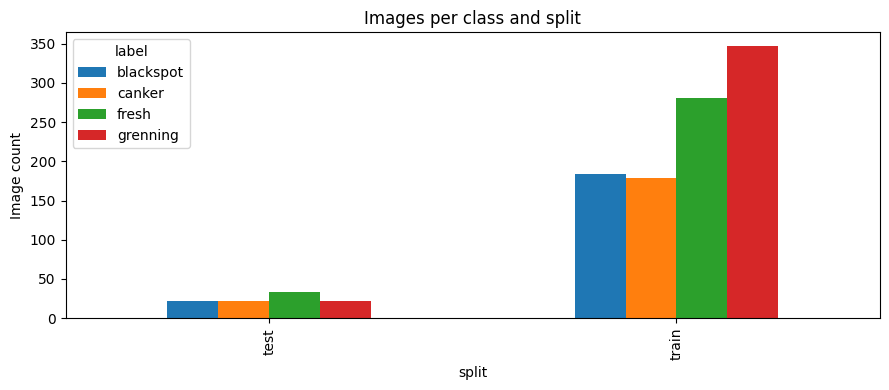

,path,split,label,width,height,mode
0,/content/data/train/blackspot/b (18).jpg,train,blackspot,800,800,RGB
1,/content/data/train/blackspot/b (71).jpg,train,blackspot,800,800,RGB
2,/content/data/train/blackspot/b (39).jpg,train,blackspot,800,800,RGB
3,/content/data/train/blackspot/b (84).jpg,train,blackspot,800,800,RGB
4,/content/data/train/blackspot/b (31).jpg,train,blackspot,800,800,RGB


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [3]:
from pathlib import Path
from PIL import Image
import pandas as pd, matplotlib.pyplot as plt, os
root=Path(DATA_DIR)
# Handle either data/train/... or data/Orange Dataset/train/... if archive contains a wrapper folder.
candidates=[p for p in root.rglob("train") if p.is_dir() and (p.parent/"test").is_dir()]
assert candidates, "Could not locate paired train/ and test/ folders. Inspect extracted folders and set DATA_ROOT."
DATA_ROOT=candidates[0].parent
print("Using dataset root:", DATA_ROOT)
rows=[]; unreadable=[]
for split in ["train","test"]:
    for cls_dir in sorted((DATA_ROOT/split).iterdir()):
        if not cls_dir.is_dir(): continue
        for p in cls_dir.rglob("*"):
            if p.suffix.lower() not in {".jpg",".jpeg",".png",".bmp",".webp"}: continue
            try:
                with Image.open(p) as im:
                    w,h=im.size
                    rows.append({"path":str(p),"split":split,"label":cls_dir.name,"width":w,"height":h,"mode":im.mode})
            except Exception:
                unreadable.append(str(p))
df=pd.DataFrame(rows)
display(df.groupby(["split","label"]).size().unstack(fill_value=0))
print("Readable images:",len(df),"Unreadable:",len(unreadable))
display(df.groupby("split")[["width","height"]].describe())
df.groupby(["split","label"]).size().unstack(fill_value=0).plot(kind="bar",figsize=(9,4))
plt.title("Images per class and split"); plt.ylabel("Image count"); plt.tight_layout(); plt.show()
display(df.head())


### Visual quality spot-check
Review these examples for blur, lighting differences, backgrounds, mislabeled images, and duplicate-looking samples. This is a spot-check.

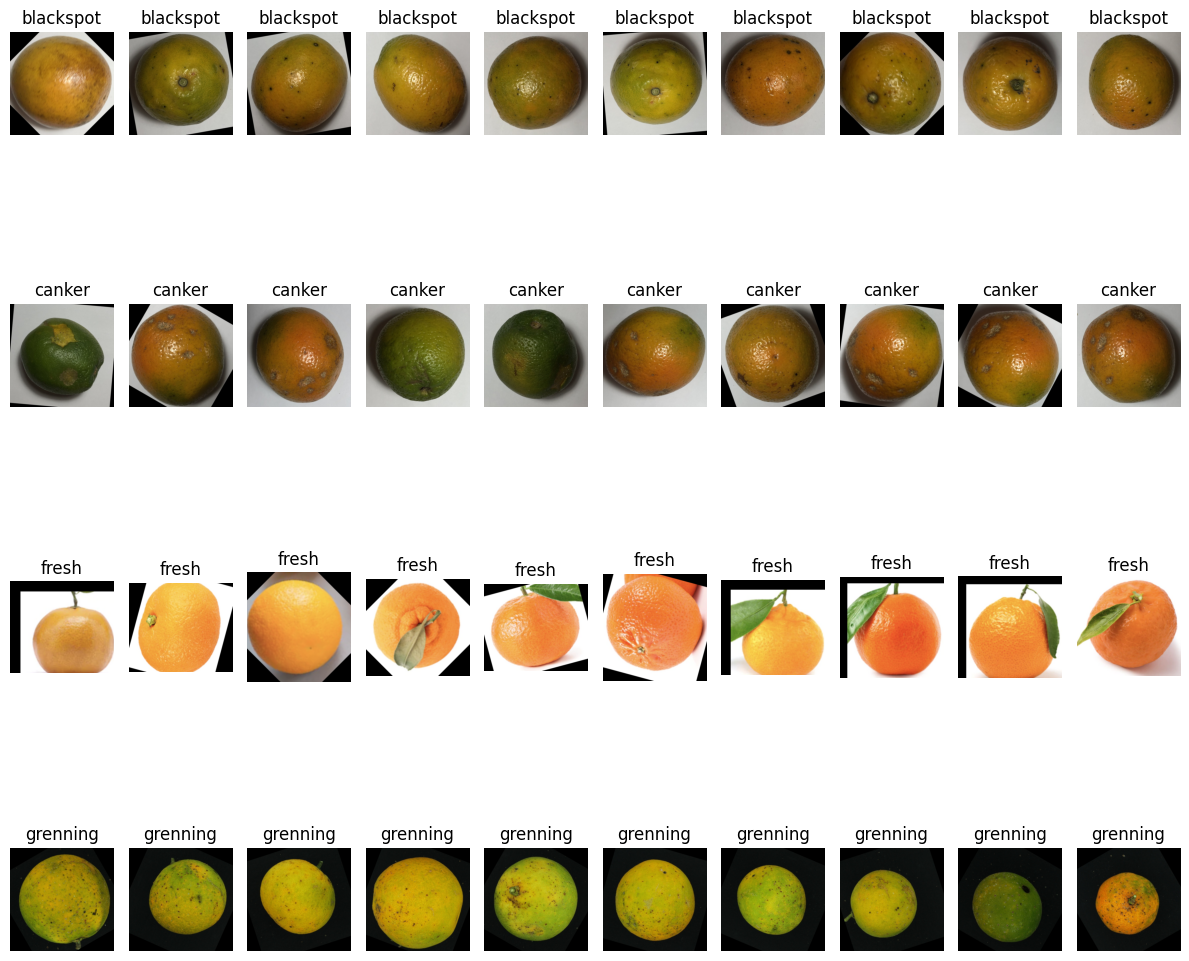

In [13]:
import random
from PIL import Image
classes=sorted(df.label.unique())
fig, axes=plt.subplots(len(classes),10,figsize=(12,3*len(classes)))
for r,cls in enumerate(classes):
    sample=df[(df.label==cls)&(df.split=="train")].sample(min(10,len(df[(df.label==cls)&(df.split=="train")])),random_state=42)
    for c,(_,row) in enumerate(sample.iterrows()):
        axes[r,c].imshow(Image.open(row.path).convert("RGB")); axes[r,c].set_title(cls); axes[r,c].axis("off")
    for c in range(len(sample),10): axes[r,c].axis("off")
plt.tight_layout(); plt.show()


## 2. Approach 1 — Classical CV (HSV + CIELAB histograms + LBP) and SVM

Validation accuracy: 0.9731543624161074
SVM TEST accuracy: 0.98989898989899
SVM TEST macro F1: 0.9886304909560724
              precision    recall  f1-score   support

   blackspot       1.00      0.95      0.98        22
      canker       0.96      1.00      0.98        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.99        99
   macro avg       0.99      0.99      0.99        99
weighted avg       0.99      0.99      0.99        99



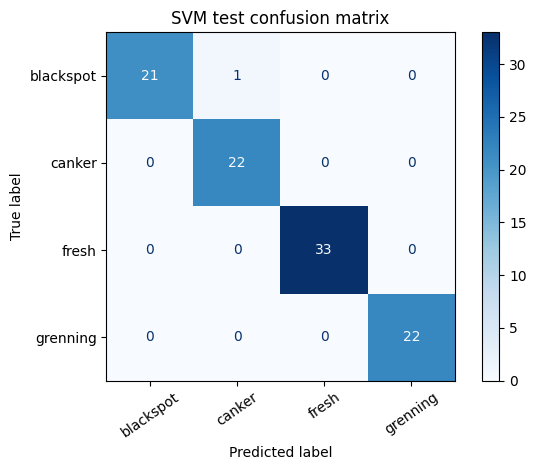

['/content/models/classical_svm.joblib']

In [14]:
import cv2, numpy as np, joblib, time
from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

def features(path, size=(128,128)):
    bgr=cv2.imread(str(path))
    if bgr is None: raise ValueError(f"Cannot read {path}")
    bgr=cv2.resize(bgr,size,interpolation=cv2.INTER_AREA)
    hsv=cv2.cvtColor(bgr,cv2.COLOR_BGR2HSV); lab=cv2.cvtColor(bgr,cv2.COLOR_BGR2LAB)
    out=[]
    for im, chs, ranges in [(hsv,[0,1,2],[[0,180],[0,256],[0,256]]),(lab,[0,1,2],[[0,256],[0,256],[0,256]])]:
        for ch,rng in zip(chs,ranges):
            h=cv2.calcHist([im],[ch],None,[16],rng).flatten(); out.extend(h/(h.sum()+1e-8))
    gray=cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY)
    lbp=local_binary_pattern(gray,8,1,method="uniform")
    h,_=np.histogram(lbp.ravel(),bins=np.arange(0,11),range=(0,10))
    out.extend(h/(h.sum()+1e-8))
    return np.asarray(out,dtype=np.float32)

train_df=df[df.split=="train"].copy(); test_df=df[df.split=="test"].copy()
X=np.stack([features(p) for p in train_df.path]); y=train_df.label.to_numpy()
X_test=np.stack([features(p) for p in test_df.path]); y_test=test_df.label.to_numpy()
X_tr,X_val,y_tr,y_val=train_test_split(X,y,test_size=.15,random_state=42,stratify=y)
svm=Pipeline([("scaler",StandardScaler()),("svc",SVC(C=3,kernel="rbf",class_weight="balanced"))])
svm.fit(X_tr,y_tr)
print("Validation accuracy:",accuracy_score(y_val,svm.predict(X_val)))
# Refit on all training data after validation
svm.fit(X,y)
pred_svm=svm.predict(X_test)
print("SVM TEST accuracy:",accuracy_score(y_test,pred_svm))
print("SVM TEST macro F1:",f1_score(y_test,pred_svm,average="macro"))
print(classification_report(y_test,pred_svm,zero_division=0))
labels=sorted(set(y)|set(y_test))
ConfusionMatrixDisplay.from_predictions(y_test,pred_svm,labels=labels,xticks_rotation=35,cmap="Blues")
plt.title("SVM test confusion matrix"); plt.tight_layout(); plt.show()
os.makedirs("/content/models",exist_ok=True)
joblib.dump({"model":svm,"labels":labels},"/content/models/classical_svm.joblib")


## 3. Approach 2 — MobileNetV2 transfer learning
In the first approch I am using ImageNet weights. In below Approch I am using "MobileNetV2" for an efficient computer vision tasks.

Device: cpu
Loaded pretrained ImageNet weights.
Epoch 1/8: train loss=0.8221, val loss=0.4642, val acc=0.9396
Epoch 2/8: train loss=0.3387, val loss=0.2694, val acc=0.9664
Epoch 3/8: train loss=0.2195, val loss=0.1896, val acc=0.9664
Epoch 4/8: train loss=0.1706, val loss=0.1621, val acc=0.9664
Epoch 5/8: train loss=0.1354, val loss=0.1437, val acc=0.9732
Epoch 6/8: train loss=0.1247, val loss=0.1277, val acc=0.9799
Epoch 7/8: train loss=0.1029, val loss=0.1167, val acc=0.9664
Epoch 8/8: train loss=0.0921, val loss=0.1123, val acc=0.9664
MobileNetV2 TEST accuracy: 0.9393939393939394
MobileNetV2 TEST macro F1: 0.9342055003819709
Total test inference time: 4.3593 seconds; average ms/image: 44.03
              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.90      0.82      0.86        22
       fresh       0.94      1.00      0.97        33
    grenning       1.00      1.00      1.00        22

    accuracy             

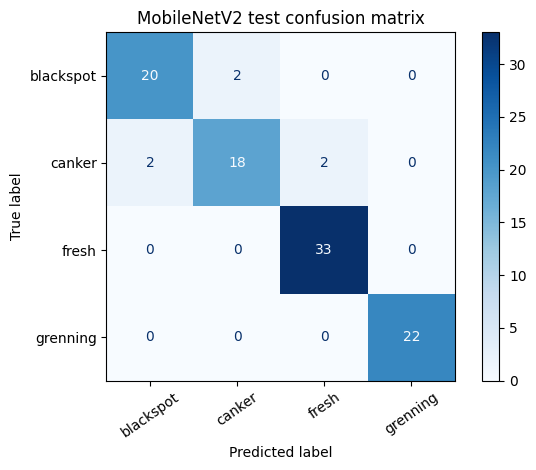

In [16]:
import torch, torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import copy, time
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)
classes=sorted(train_df.label.unique()); class_to_idx={c:i for i,c in enumerate(classes)}
tr_rows,val_rows=train_test_split(train_df[["path","label"]].values.tolist(),test_size=.15,random_state=42,stratify=train_df.label)
mean=(0.485,0.456,0.406); std=(0.229,0.224,0.225)
train_tf=transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(),transforms.RandomRotation(10),transforms.ColorJitter(brightness=.12,contrast=.12,saturation=.1),transforms.ToTensor(),transforms.Normalize(mean,std)])
eval_tf=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(mean,std)])
class ImgDS(Dataset):
    def __init__(self,rows,tf): self.rows=rows; self.tf=tf
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        p,l=self.rows[i]; return self.tf(Image.open(p).convert("RGB")),class_to_idx[l]
train_ds=ImgDS(tr_rows,train_tf); val_ds=ImgDS(val_rows,eval_tf)
test_rows=test_df[["path","label"]].values.tolist(); test_ds=ImgDS(test_rows,eval_tf)
train_dl=DataLoader(train_ds,batch_size=32,shuffle=True,num_workers=2)
val_dl=DataLoader(val_ds,batch_size=32,shuffle=False,num_workers=2)
test_dl=DataLoader(test_ds,batch_size=32,shuffle=False,num_workers=2)
try:
    model=models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    print("Loaded pretrained ImageNet weights.")
except Exception as e:
    print("WARNING: pretrained weights could not be loaded; using random initialization:",e)
    model=models.mobilenet_v2(weights=None)
for p in model.features.parameters(): p.requires_grad=False
model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(classes))
model=model.to(device)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.classifier.parameters(),lr=1e-3)
best=copy.deepcopy(model.state_dict()); best_loss=float("inf"); patience=3; bad=0
EPOCHS=8
for epoch in range(EPOCHS):
    model.train(); total=0
    for xb,yb in train_dl:
        xb,yb=xb.to(device),yb.to(device); optimizer.zero_grad()
        loss=criterion(model(xb),yb); loss.backward(); optimizer.step(); total+=loss.item()*len(yb)
    model.eval(); vloss=0; correct=0; n=0
    with torch.no_grad():
        for xb,yb in val_dl:
            xb,yb=xb.to(device),yb.to(device); logits=model(xb)
            vloss+=criterion(logits,yb).item()*len(yb); correct+=(logits.argmax(1)==yb).sum().item(); n+=len(yb)
    vloss/=n; vacc=correct/n
    print(f"Epoch {epoch+1}/{EPOCHS}: train loss={total/len(train_ds):.4f}, val loss={vloss:.4f}, val acc={vacc:.4f}")
    if vloss<best_loss: best_loss=vloss; best=copy.deepcopy(model.state_dict()); bad=0
    else:
        bad+=1
        if bad>=patience: print("Early stopping"); break
model.load_state_dict(best); model.eval()
yt=[]; yp=[]; t0=time.perf_counter(); n_imgs=0
with torch.no_grad():
    for xb,yb in test_dl:
        logits=model(xb.to(device)); yp.extend(logits.argmax(1).cpu().numpy()); yt.extend(yb.numpy()); n_imgs+=len(yb)
elapsed=time.perf_counter()-t0
print("MobileNetV2 TEST accuracy:",accuracy_score(yt,yp))
print("MobileNetV2 TEST macro F1:",f1_score(yt,yp,average="macro"))
print("Total test inference time:",round(elapsed,4),"seconds; average ms/image:",round(elapsed/max(n_imgs,1)*1000,2))
print(classification_report(yt,yp,target_names=classes,zero_division=0))
ConfusionMatrixDisplay.from_predictions([classes[i] for i in yt],[classes[i] for i in yp],labels=classes,xticks_rotation=35,cmap="Blues")
plt.title("MobileNetV2 test confusion matrix"); plt.tight_layout(); plt.show()
torch.save({"state_dict":model.state_dict(),"classes":classes,"mean":mean,"std":std},"/content/models/mobilenetv2.pth")


## 4. Compare models
Use the actual printed test metrics. Macro F1 is important if class counts differ; inspect per-class recall and confusion matrices rather than selecting on accuracy alone.

In [17]:
results=pd.DataFrame([
 {"Model":"Classical SVM","Test accuracy":accuracy_score(y_test,pred_svm),"Macro F1":f1_score(y_test,pred_svm,average="macro")},
 {"Model":"MobileNetV2","Test accuracy":accuracy_score(yt,yp),"Macro F1":f1_score(yt,yp,average="macro")}
])
display(results)


,Model,Test accuracy,Macro F1
0,Classical SVM,0.989899,0.988630
1,MobileNetV2,0.939394,0.934206


## 5. One-image demonstration with both models

Saving c (13).jpg to c (13).jpg
Classical SVM prediction: canker
MobileNetV2 prediction: canker
Class probabilities: {'blackspot': 0.0652, 'canker': 0.8929, 'fresh': 0.0366, 'grenning': 0.0054}


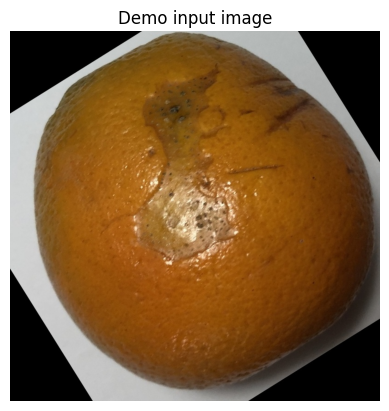

In [18]:
from google.colab import files
up=files.upload()  # upload one sample image
IMAGE_PATH=next(iter(up))
pack=joblib.load("/content/models/classical_svm.joblib")
print("Classical SVM prediction:",pack["model"].predict(features(IMAGE_PATH).reshape(1,-1))[0])
img=Image.open(IMAGE_PATH).convert("RGB")
with torch.no_grad():
    logits=model(eval_tf(img).unsqueeze(0).to(device))
    probs=torch.softmax(logits,dim=1)[0].cpu().numpy()
idx=int(np.argmax(probs))
print("MobileNetV2 prediction:",classes[idx])
print("Class probabilities:",{c:round(float(probs[i]),4) for i,c in enumerate(classes)})
plt.imshow(img); plt.axis("off"); plt.title("Demo input image"); plt.show()
